In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import math
import copy

print(" Импорты выполнены")
print("cv2:", cv2.__version__)
print("numpy:", np.__version__)

 Импорты выполнены
cv2: 4.11.0
numpy: 2.4.6


In [17]:
#  КРИТЕРИЙ 1: среднее (из лекции) 
def homo_average(img, mask, point, T):
    """|avg(region) - img[point]| <= T"""
    if np.count_nonzero(mask > 0) == 0:
        return False
    av_val = img[mask > 0].sum() / np.count_nonzero(mask > 0)
    return abs(av_val - img[point]) <= T


# КРИТЕРИЙ 2: дисперсия региона 
def homo_variance(img, mask, point, T):
    """Добавление точки не увеличивает СКО региона выше T."""
    if np.count_nonzero(mask > 0) == 0:
        return True
    old_vals = img[mask > 0].astype(np.float32)
    new_vals = np.append(old_vals, img[point])
    return new_vals.std() <= T


#  КРИТЕРИЙ 3: медиана
def homo_median(img, mask, point, T):
    """|median(region) - img[point]| <= T"""
    if np.count_nonzero(mask > 0) == 0:
        return False
    med = np.median(img[mask > 0])
    return abs(med - img[point]) <= T


print(" Три критерия однородности определены")

 Три критерия однородности определены


In [18]:
def region_growing(image, seed_point, homo_func, r, T, max_iter=5000):
    """
    image      — серое изображение
    seed_point — (row, col)
    homo_func  — функция критерия однородности
    r          — радиус окрестности
    T          — порог
    """
    mask = np.zeros(image.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    iteration = 0

    while count > 0 and iteration < max_iter:
        iteration += 1
        count = 0
        local_mask = np.zeros(image.shape, np.uint8)

        for i in range(r, image.shape[0] - r):
            for j in range(r, image.shape[1] - r):
                if mask[i, j] == 0 and mask[i-r:i+r, j-r:j+r].sum() > 0:
                    if homo_func(image, mask, (i, j), T):
                        local_mask[i, j] = 1

        count = np.count_nonzero(local_mask)
        mask += local_mask

    print(f"  Итераций: {iteration}, пикселей: {np.count_nonzero(mask)}")
    return mask * 255


print(" Функция region_growing определена")

 Функция region_growing определена


shape = (300, 400)
mean = 91.82


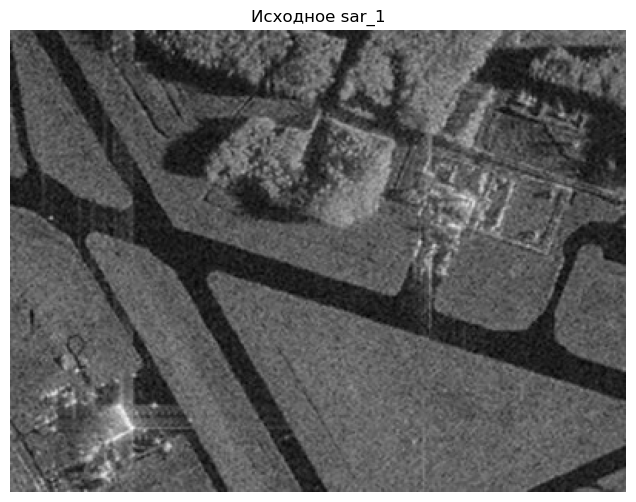

In [4]:
# Загрузка sar_1 
image = cv2.imread('sar_1.jpg')
if image is None:
    image = cv2.imread('sar_1_gray.jpg')
if image is None:
    raise FileNotFoundError("Не найден sar_1.jpg / sar_1_gray.jpg")

image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image

print("shape =", image_gray.shape)
print("mean =", round(float(image_gray.mean()), 2))

plt.figure(figsize=(8, 6))
plt.imshow(image_gray, cmap='gray')
plt.title('Исходное sar_1')
plt.axis('off')
plt.show()

Уменьшенный размер: (150, 200)


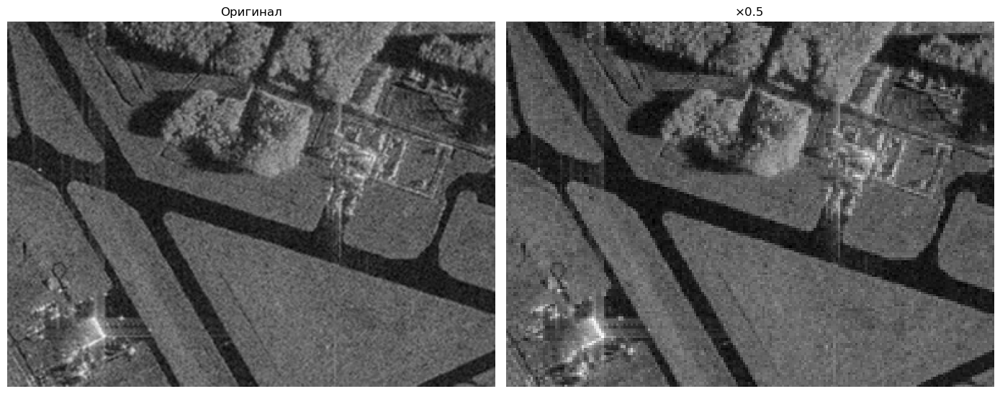

In [5]:
scale = 0.5
image_small = cv2.resize(image_gray, (0, 0), fx=scale, fy=scale)

print("Уменьшенный размер:", image_small.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(image_gray, cmap='gray'); axes[0].set_title('Оригинал'); axes[0].axis('off')
axes[1].imshow(image_small, cmap='gray'); axes[1].set_title(f'×{scale}'); axes[1].axis('off')
plt.tight_layout(); plt.show()

Яркость точки (60, 60): 85


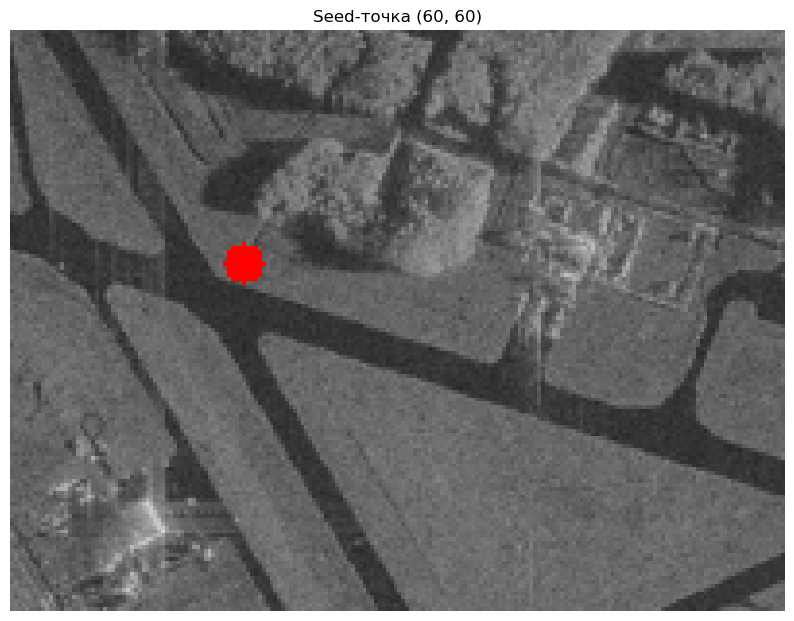

In [6]:
#  Seed-точка внутри газона (row, col) 
seed_point = (60, 60)

# Проверим яркость
print(f"Яркость точки {seed_point}: {image_small[seed_point]}")

# Нарисуем точку на изображении
img_marked = cv2.cvtColor(image_small.copy(), cv2.COLOR_GRAY2BGR)
cv2.circle(img_marked, (seed_point[1], seed_point[0]), 5, (0, 0, 255), -1)

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(img_marked, cv2.COLOR_BGR2RGB))
plt.title(f'Seed-точка {seed_point}')
plt.axis('off'); plt.show()


--- T = 5 ---
  Итераций: 8, пикселей: 22

--- T = 10 ---
  Итераций: 80, пикселей: 809

--- T = 20 ---
  Итераций: 120, пикселей: 2021

--- T = 40 ---
  Итераций: 147, пикселей: 10570


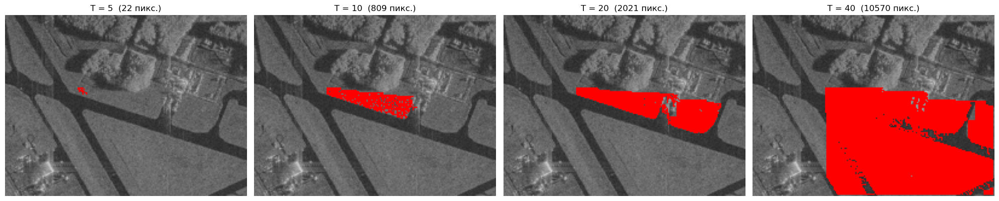

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for ax, T in zip(axes, [5, 10, 20, 40]):
    print(f"\n--- T = {T} ---")
    mask = region_growing(image_small, seed_point, homo_average, r=1, T=T)
    result = cv2.cvtColor(image_small.copy(), cv2.COLOR_GRAY2BGR)
    result[mask > 0] = [0, 0, 255]

    ax.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    ax.set_title(f'T = {T}  ({np.count_nonzero(mask)} пикс.)')
    ax.axis('off')

plt.tight_layout(); plt.show()

ЗАДАНИЕ 1: РЕЗУЛЬТАТ
  Итераций: 80, пикселей: 809


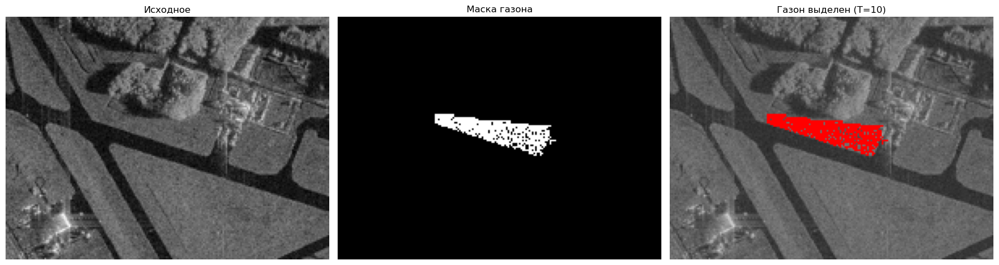

Seed-точка:   (60, 60)
Порог T:      10
Пикселей:     809
Площадь %:    2.70%


In [19]:
T_best = 10 

print("=" * 50)
print("ЗАДАНИЕ 1: РЕЗУЛЬТАТ")
print("=" * 50)

mask_lawn = region_growing(image_small, seed_point, homo_average, r=1, T=T_best)

result_lawn = cv2.cvtColor(image_small.copy(), cv2.COLOR_GRAY2BGR)
result_lawn[mask_lawn > 0] = [0, 0, 255]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(image_small, cmap='gray'); axes[0].set_title('Исходное'); axes[0].axis('off')
axes[1].imshow(mask_lawn, cmap='gray');   axes[1].set_title('Маска газона'); axes[1].axis('off')
axes[2].imshow(cv2.cvtColor(result_lawn, cv2.COLOR_BGR2RGB))
axes[2].set_title(f'Газон выделен (T={T_best})'); axes[2].axis('off')
plt.tight_layout(); plt.show()

print(f"Seed-точка:   {seed_point}")
print(f"Порог T:      {T_best}")
print(f"Пикселей:     {np.count_nonzero(mask_lawn)}")
print(f"Площадь %:    {100 * np.count_nonzero(mask_lawn) / image_small.size:.2f}%")


=== Среднее ===
  Итераций: 80, пикселей: 809

=== Дисперсия ===
  Итераций: 16, пикселей: 140

=== Медиана ===
  Итераций: 75, пикселей: 842


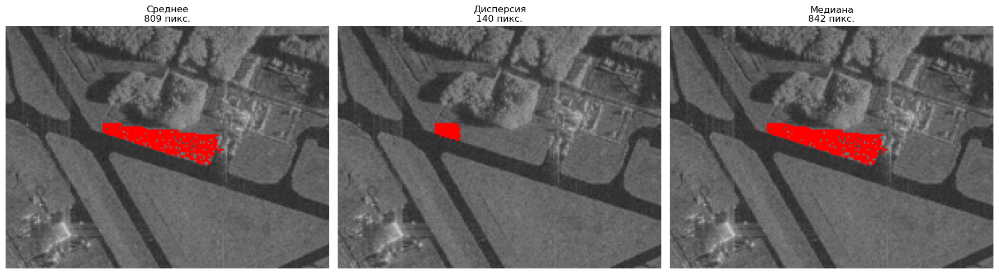


СРАВНЕНИЕ КРИТЕРИЕВ
Критерий                 Пикселей
---------------------------------------------
Среднее                       809
Дисперсия                     140
Медиана                       842


In [9]:
T_best = 10

criteria = {
    'Среднее':   homo_average,
    'Дисперсия': homo_variance,
    'Медиана':   homo_median,
}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
results_criteria = {}

for ax, (name, func) in zip(axes, criteria.items()):
    print(f"\n=== {name} ===")
    mask = region_growing(image_small, seed_point, func, r=1, T=T_best)
    results_criteria[name] = mask

    result = cv2.cvtColor(image_small.copy(), cv2.COLOR_GRAY2BGR)
    result[mask > 0] = [0, 0, 255]

    ax.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    ax.set_title(f'{name}\n{np.count_nonzero(mask)} пикс.')
    ax.axis('off')

plt.tight_layout(); plt.show()

print("\n" + "=" * 45)
print("СРАВНЕНИЕ КРИТЕРИЕВ")
print("=" * 45)
print(f"{'Критерий':<22} {'Пикселей':>10}")
print("-" * 45)
for name, m in results_criteria.items():
    print(f"{name:<22} {np.count_nonzero(m):>10}")

 Загружен: palm_1.JPG
shape = (527, 535) dtype = uint8
mean = 158.75


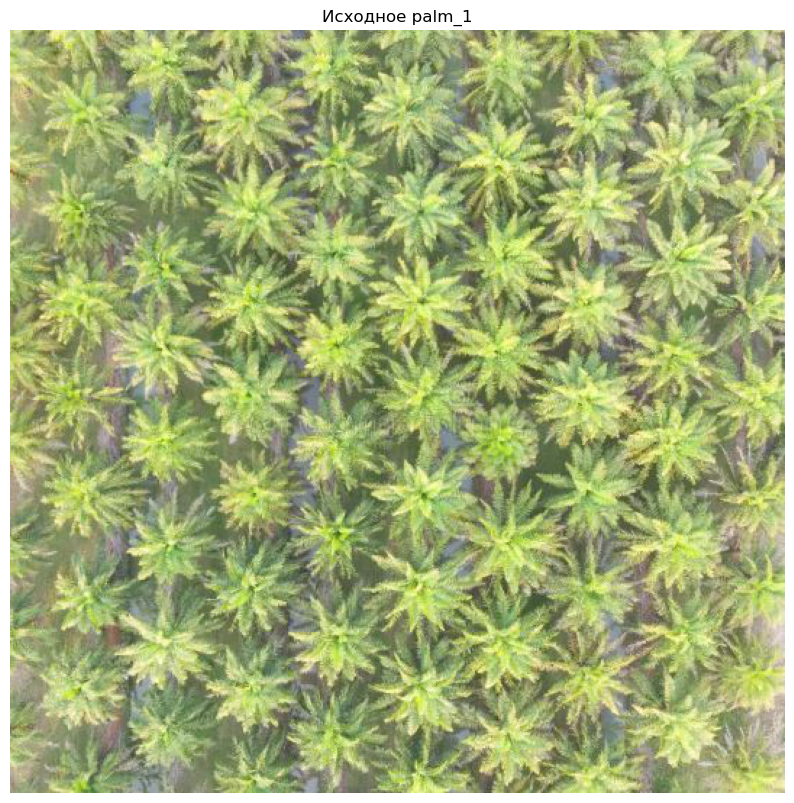

In [20]:
import os

# Ищем palm_1 с любым расширением и регистром
image_palms = None
for f in os.listdir('.'):
    if f.lower().startswith('palm_1'):
        image_palms = cv2.imread(f)
        print(f" Загружен: {f}")
        break

if image_palms is None:
    print(" Файл palm_1.* не найден. Доступные:")
    for f in os.listdir('.'):
        if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
            print("  •", f)
    raise FileNotFoundError("Проверьте имя файла")

image_palms_gray = cv2.cvtColor(image_palms, cv2.COLOR_BGR2GRAY)

print("shape =", image_palms_gray.shape, "dtype =", image_palms_gray.dtype)
print("mean =", round(float(image_palms_gray.mean()), 2))

plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(image_palms, cv2.COLOR_BGR2RGB))
plt.title('Исходное palm_1')
plt.axis('off'); plt.show()

Порог Отсу: 158.0


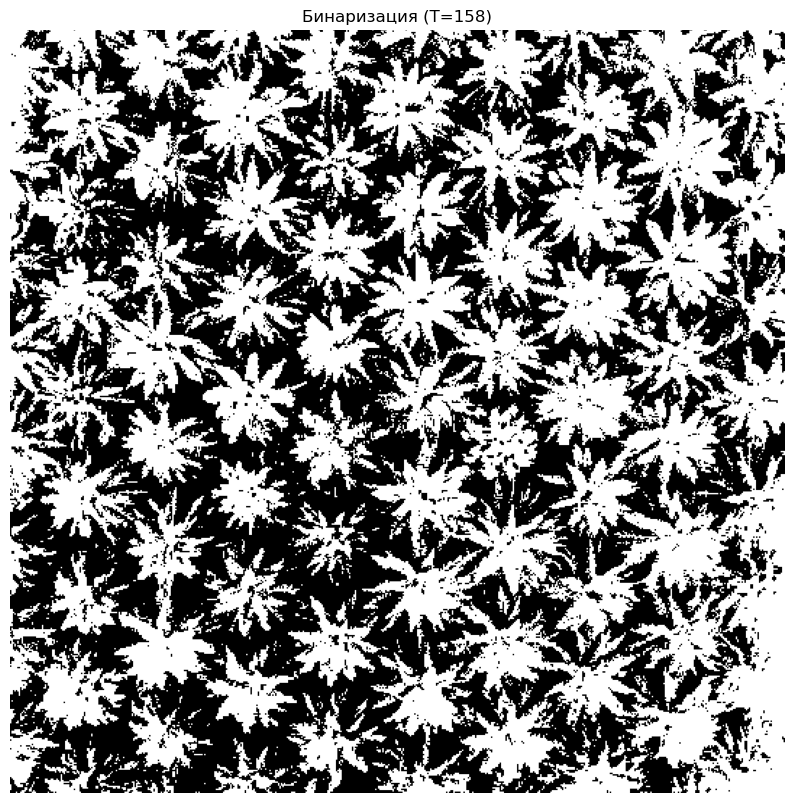

In [11]:
ret_otsu, thresh = cv2.threshold(image_palms_gray, 0, 255,
                                 cv2.THRESH_BINARY + cv2.THRESH_OTSU)

print(f"Порог Отсу: {ret_otsu}")

plt.figure(figsize=(10, 10))
plt.imshow(thresh, cmap='gray')
plt.title(f'Бинаризация (T={ret_otsu:.0f})')
plt.axis('off'); plt.show()

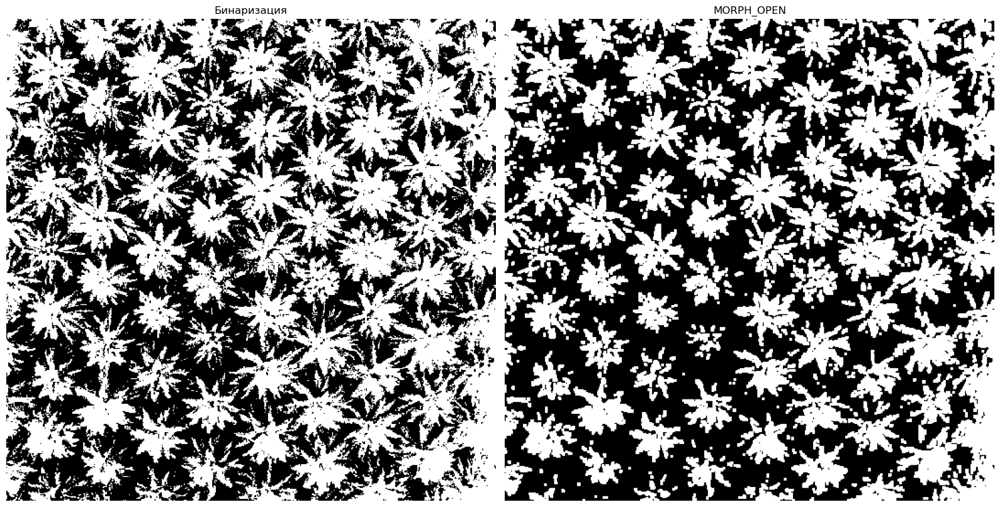

In [12]:
kernel = np.ones((3, 3), np.uint8)
opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=1)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(thresh, cmap='gray');  axes[0].set_title('Бинаризация'); axes[0].axis('off')
axes[1].imshow(opening, cmap='gray'); axes[1].set_title('MORPH_OPEN');  axes[1].axis('off')
plt.tight_layout(); plt.show()

Ядер (пальм): 392
sure_fg:      121874
sure_bg:      61881
unknown:      98190

 Watershed: пальм = 392


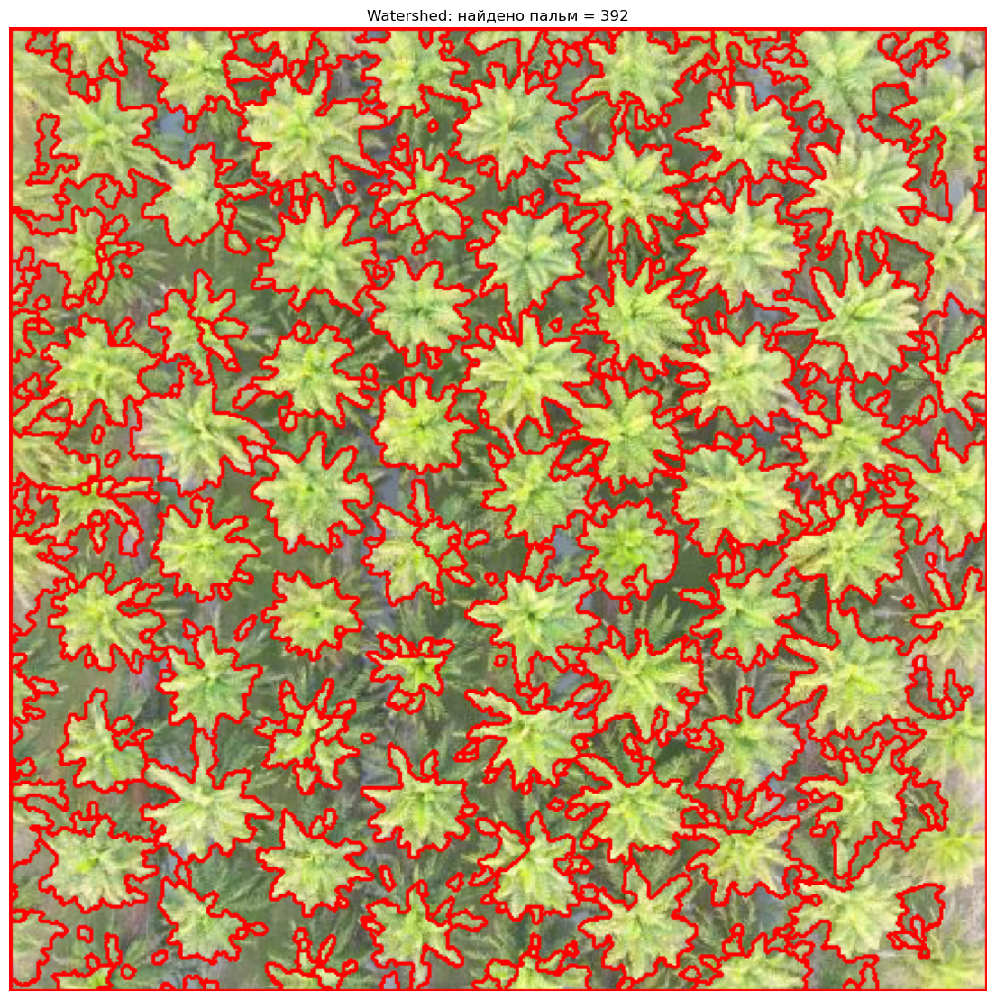

In [21]:
# SURE_FG = вся крона пальм
sure_fg = opening.copy()

# SURE_BG = фон между пальмами
sure_bg = cv2.dilate(sure_fg, kernel, iterations=3)
sure_bg = cv2.bitwise_not(sure_bg)

# UNKNOWN = тонкая полоса по границам
unknown = cv2.bitwise_and(cv2.bitwise_not(sure_fg),
                          cv2.bitwise_not(sure_bg))

# Маркеры
ret, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

print(f"Ядер (пальм): {ret - 1}")
print(f"sure_fg:      {np.count_nonzero(sure_fg)}")
print(f"sure_bg:      {np.count_nonzero(sure_bg)}")
print(f"unknown:      {np.count_nonzero(unknown)}")

# Watershed
markers = cv2.watershed(image_palms, markers)
print(f"\n Watershed: пальм = {ret - 1}")

# Границы — красным
boundaries = np.zeros(markers.shape, np.uint8)
boundaries[markers == -1] = 255
boundaries = cv2.dilate(boundaries, np.ones((2, 2), np.uint8))

image_result = image_palms.copy()
image_result[boundaries == 255] = [0, 0, 255]

plt.figure(figsize=(14, 14))
plt.imshow(cv2.cvtColor(image_result, cv2.COLOR_BGR2RGB))
plt.title(f'Watershed: найдено пальм = {ret - 1}')
plt.axis('off'); plt.show()

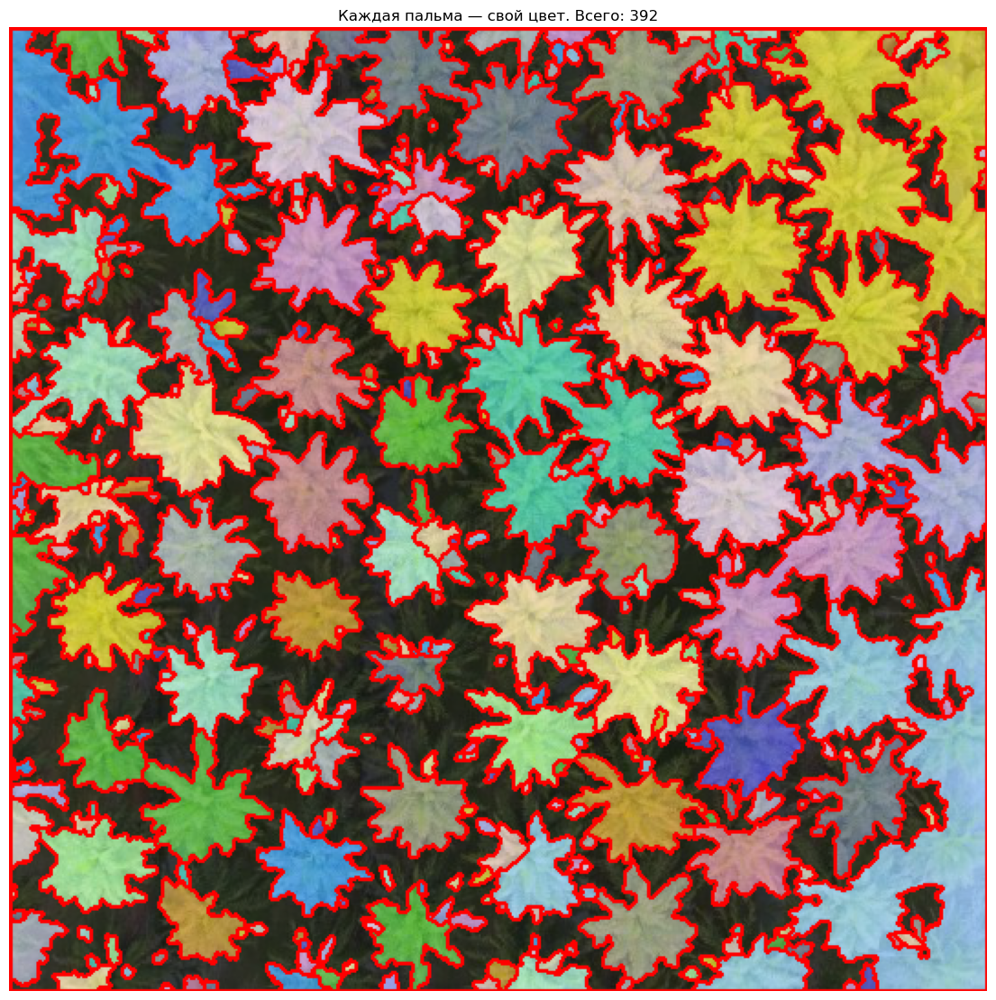


 ИТОГ: подсчитано 392 пальмовых деревьев


In [22]:
from matplotlib import cm
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Палитра
colors = cm.tab20(np.linspace(0, 1, 20))[:, :3]
colors = (colors * 255).astype(np.uint8)

# Раскраска по маркерам
colored = np.zeros_like(image_palms)
for i in range(2, ret + 1):
    obj_mask = (markers == i)
    colored[obj_mask] = colors[i % 20]

# Наложение
overlay = cv2.addWeighted(image_palms, 0.35, colored, 0.65, 0)

# Красные границы поверх
overlay[boundaries == 255] = [0, 0, 255]

plt.figure(figsize=(14, 14))
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.title(f'Каждая пальма — свой цвет. Всего: {ret - 1}')
plt.axis('off'); plt.show()

print(f"\n ИТОГ: подсчитано {ret - 1} пальмовых деревьев")